In [14]:
!find data -maxdepth 2 -type d

data
data/Rice_Leaf_AUG
data/Rice_Leaf_AUG/Bacterial Leaf Blight
data/Rice_Leaf_AUG/Leaf scald
data/Rice_Leaf_AUG/Healthy Rice Leaf
data/Rice_Leaf_AUG/Sheath Blight
data/Rice_Leaf_AUG/Leaf Blast
data/Rice_Leaf_AUG/Brown Spot


In [28]:
!zip -r results.zip results

updating: results/ (stored 0%)
updating: results/confusion_matrices.png (deflated 13%)
updating: results/errors_fine-tuned.png (deflated 0%)
updating: results/training_curves.png (deflated 8%)
updating: results/errors_baseline.png (deflated 0%)
updating: results/summary.csv (deflated 15%)


In [15]:
!nvidia-smi

Thu Nov 26 01:11:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Lab 03: Transfer Learning for Image Classification
**Problem:** Classify rice leaf diseases from photos.

**Author:** Arandela, Jherrymei D.

**Goal:** Fine-tune a pretrained CNN (ResNet18, ImageNet weights) and compare it with a
baseline CNN trained from scratch on the *same* data split, using training curves and error analysis.

**Dataset layout expected** (e.g. Kaggle "Rice Leaf Disease" or PlantVillage subset):
```
Lab03/data/rice_leaf/
    Bacterial_leaf_blight/*.jpg
    Brown_spot/*.jpg
    Leaf_smut/*.jpg
```
(one folder per class; folder names become labels).

In [16]:
import random, copy, time
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path("data/Rice_Leaf_AUG")
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
IMG_SIZE, BATCH_SIZE, EPOCHS = 128, 32, 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 1. Data: one fixed stratified split shared by both models

In [17]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Two views of the same files: augmentation only for training.
full_train_view = datasets.ImageFolder(DATA_DIR, transform=train_tf)
full_eval_view = datasets.ImageFolder(DATA_DIR, transform=eval_tf)
class_names = full_train_view.classes
targets = np.array(full_train_view.targets)
print("Classes:", class_names, "| images:", len(targets))

def stratified_split(targets, fractions=(0.7, 0.15, 0.15), seed=SEED):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(targets):
        idx = rng.permutation(np.where(targets == c)[0])
        n_tr, n_va = int(len(idx) * fractions[0]), int(len(idx) * fractions[1])
        tr += idx[:n_tr].tolist(); va += idx[n_tr:n_tr + n_va].tolist(); te += idx[n_tr + n_va:].tolist()
    return tr, va, te

train_idx, val_idx, test_idx = stratified_split(targets)
print(f"train={len(train_idx)} val={len(val_idx)} test={len(test_idx)}")

train_loader = DataLoader(Subset(full_train_view, train_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(full_eval_view, val_idx), batch_size=BATCH_SIZE, num_workers=2)
test_loader = DataLoader(Subset(full_eval_view, test_idx), batch_size=BATCH_SIZE, num_workers=2)

Classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight'] | images: 3829
train=2678 val=571 test=580


## 2. Models
- **Fine-tuned ResNet18:** ImageNet weights, new classification head, only `layer4` + head are trainable.
- **Baseline CNN:** small 4-block CNN with random weights, trained from scratch.

In [18]:
num_classes = len(class_names)

def build_finetuned():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, num_classes)   # new head (trainable)
    return m

class BaselineCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

## 3. Training loop (identical for both models)

In [19]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n

def train_model(model, lr, name):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if va > best_acc:                       # keep best epoch by VALIDATION accuracy
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:02d} | train {tl:.3f}/{ta:.3f} | val {vl:.3f}/{va:.3f}")
    model.load_state_dict(best_state)
    hist["seconds"] = time.time() - t0
    return model, hist

In [20]:
finetuned, h_ft = train_model(build_finetuned(), lr=1e-3, name="fine-tuned")
scratch, h_sc = train_model(BaselineCNN(num_classes), lr=1e-3, name="scratch")

for name, m in [("Fine-tuned ResNet18", finetuned), ("Baseline CNN", scratch)]:
    tot, tr = count_params(m)
    print(f"{name}: total params={tot:,} trainable={tr:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 226MB/s]


[fine-tuned] epoch 01 | train 0.994/0.656 | val 0.613/0.771
[fine-tuned] epoch 02 | train 0.516/0.813 | val 0.524/0.839
[fine-tuned] epoch 03 | train 0.354/0.873 | val 0.479/0.849
[fine-tuned] epoch 04 | train 0.282/0.900 | val 0.422/0.884
[fine-tuned] epoch 05 | train 0.266/0.918 | val 0.335/0.905
[fine-tuned] epoch 06 | train 0.211/0.932 | val 0.416/0.886
[fine-tuned] epoch 07 | train 0.207/0.928 | val 0.346/0.877
[fine-tuned] epoch 08 | train 0.174/0.938 | val 0.279/0.930
[scratch] epoch 01 | train 1.330/0.489 | val 1.121/0.613
[scratch] epoch 02 | train 1.100/0.612 | val 0.954/0.644
[scratch] epoch 03 | train 1.024/0.624 | val 1.183/0.608
[scratch] epoch 04 | train 0.978/0.646 | val 0.941/0.676
[scratch] epoch 05 | train 0.923/0.659 | val 0.856/0.704
[scratch] epoch 06 | train 0.883/0.680 | val 0.929/0.623
[scratch] epoch 07 | train 0.858/0.684 | val 0.783/0.713
[scratch] epoch 08 | train 0.826/0.694 | val 0.749/0.708
Fine-tuned ResNet18: total params=11,179,590 trainable=8,396,806

## 4. Side-by-side training curves

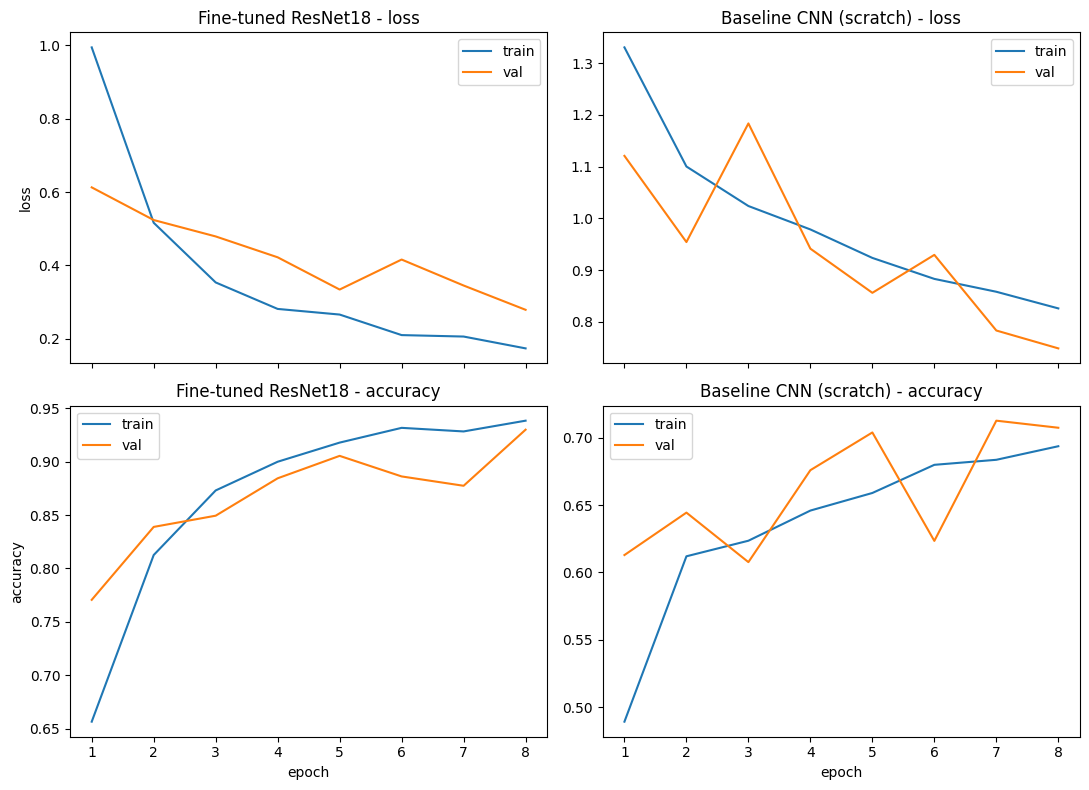

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for col, (title, h) in enumerate([("Fine-tuned ResNet18", h_ft), ("Baseline CNN (scratch)", h_sc)]):
    ep = range(1, EPOCHS + 1)
    axes[0, col].plot(ep, h["train_loss"], label="train"); axes[0, col].plot(ep, h["val_loss"], label="val")
    axes[0, col].set_title(f"{title} - loss"); axes[0, col].legend()
    axes[1, col].plot(ep, h["train_acc"], label="train"); axes[1, col].plot(ep, h["val_acc"], label="val")
    axes[1, col].set_title(f"{title} - accuracy"); axes[1, col].legend(); axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss"); axes[1, 0].set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_curves.png", dpi=150); plt.show()

## 5. Test-set evaluation and error analysis

In [22]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps += model(x.to(DEVICE)).argmax(1).cpu().tolist()
        ys += y.tolist()
    return np.array(ys), np.array(ps)

y_true, pred_ft = predict(finetuned, test_loader)
_, pred_sc = predict(scratch, test_loader)

for name, p in [("Fine-tuned ResNet18", pred_ft), ("Baseline CNN", pred_sc)]:
    print(f"\n=== {name} | test accuracy = {(p == y_true).mean():.3f} ===")
    print(classification_report(y_true, p, target_names=class_names, digits=3))


=== Fine-tuned ResNet18 | test accuracy = 0.934 ===
                       precision    recall  f1-score   support

Bacterial Leaf Blight      0.892     0.948     0.919        96
           Brown Spot      0.946     0.888     0.916        98
    Healthy Rice Leaf      1.000     0.980     0.990        99
           Leaf Blast      0.871     0.917     0.893        96
           Leaf scald      0.933     0.874     0.902        95
        Sheath Blight      0.970     1.000     0.985        96

             accuracy                          0.934       580
            macro avg      0.935     0.934     0.934       580
         weighted avg      0.936     0.934     0.934       580


=== Baseline CNN | test accuracy = 0.740 ===
                       precision    recall  f1-score   support

Bacterial Leaf Blight      0.744     0.698     0.720        96
           Brown Spot      0.597     0.847     0.700        98
    Healthy Rice Leaf      0.839     0.949     0.891        99
           Leaf

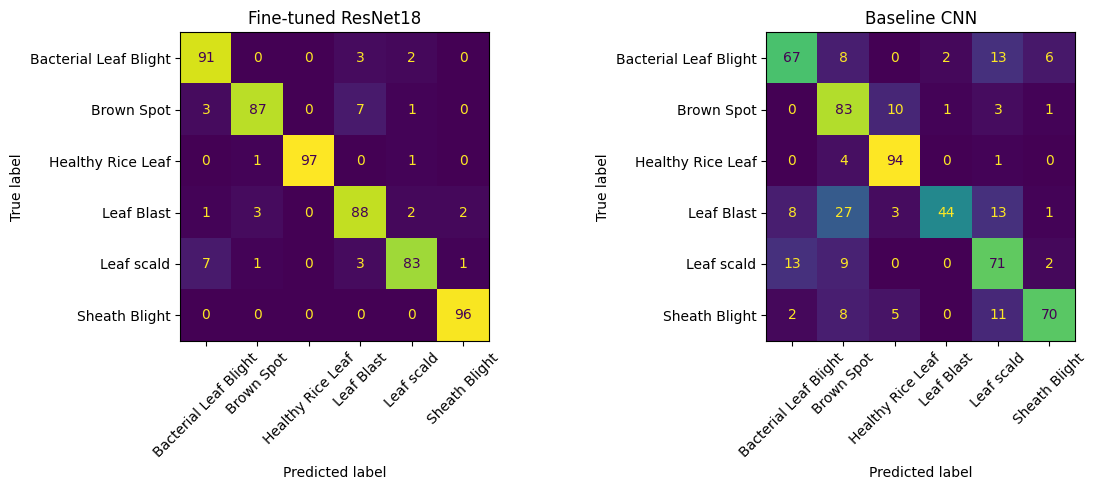

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, p) in zip(axes, [("Fine-tuned ResNet18", pred_ft), ("Baseline CNN", pred_sc)]):
    ConfusionMatrixDisplay(confusion_matrix(y_true, p), display_labels=class_names).plot(
        ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150); plt.show()

### Misclassified sample breakdown

In [24]:
def breakdown(name, p):
    wrong = np.where(p != y_true)[0]
    pairs = Counter((class_names[y_true[i]], class_names[p[i]]) for i in wrong)
    print(f"\n{name}: {len(wrong)}/{len(y_true)} misclassified")
    for (t, q), c in pairs.most_common():
        print(f"  true={t:25s} predicted={q:25s} x{c}")
    return set(wrong.tolist())

wrong_ft = breakdown("Fine-tuned ResNet18", pred_ft)
wrong_sc = breakdown("Baseline CNN", pred_sc)
print(f"\nWrong in BOTH: {len(wrong_ft & wrong_sc)} | only fine-tuned: {len(wrong_ft - wrong_sc)} | "
      f"only scratch: {len(wrong_sc - wrong_ft)}")


Fine-tuned ResNet18: 38/580 misclassified
  true=Brown Spot                predicted=Leaf Blast                x7
  true=Leaf scald                predicted=Bacterial Leaf Blight     x7
  true=Bacterial Leaf Blight     predicted=Leaf Blast                x3
  true=Brown Spot                predicted=Bacterial Leaf Blight     x3
  true=Leaf Blast                predicted=Brown Spot                x3
  true=Leaf scald                predicted=Leaf Blast                x3
  true=Bacterial Leaf Blight     predicted=Leaf scald                x2
  true=Leaf Blast                predicted=Sheath Blight             x2
  true=Leaf Blast                predicted=Leaf scald                x2
  true=Brown Spot                predicted=Leaf scald                x1
  true=Healthy Rice Leaf         predicted=Brown Spot                x1
  true=Healthy Rice Leaf         predicted=Leaf scald                x1
  true=Leaf Blast                predicted=Bacterial Leaf Blight     x1
  true=Leaf scald    

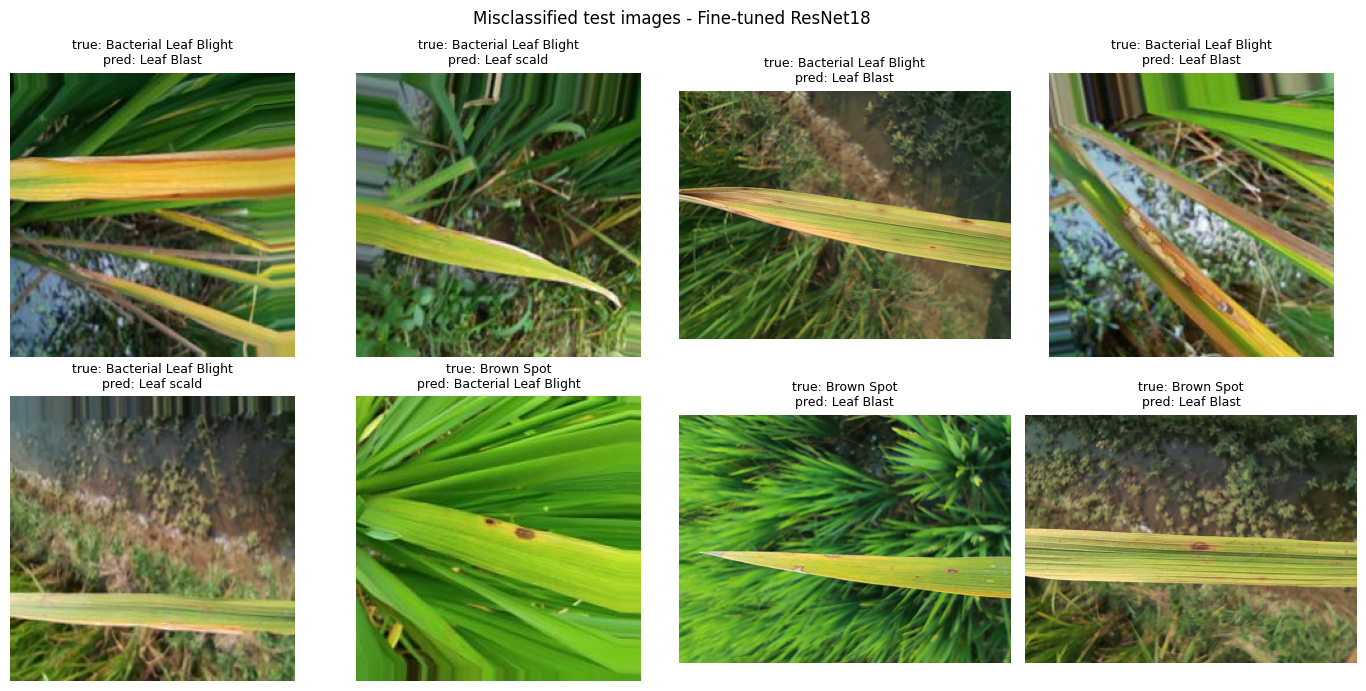

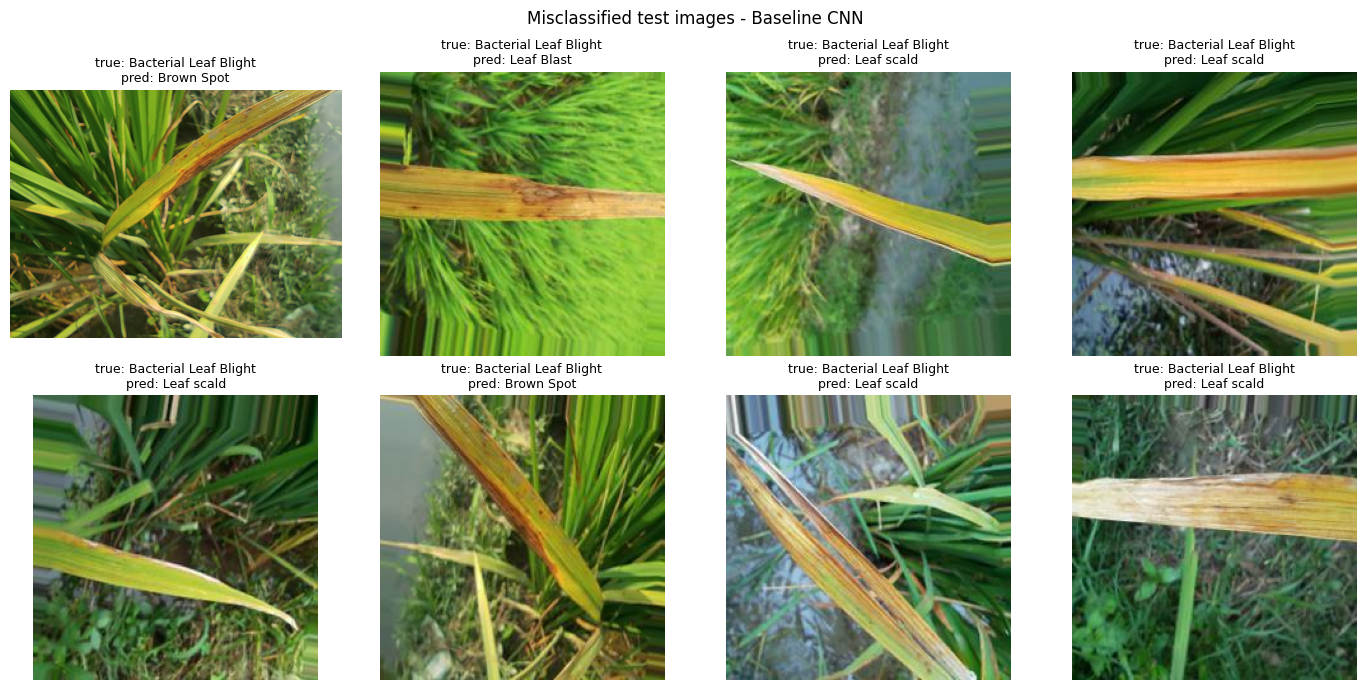

In [25]:
def show_errors(name, p, wrong, max_n=8):
    wrong = sorted(wrong)[:max_n]
    if not wrong:
        print(f"{name}: no errors to show"); return
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        path, _ = full_eval_view.samples[test_idx[i]]
        ax.imshow(plt.imread(path))
        ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[p[i]]}", fontsize=9)
    fig.suptitle(f"Misclassified test images - {name}")
    plt.tight_layout(); plt.savefig(RESULTS_DIR / f"errors_{name.split()[0].lower()}.png", dpi=150); plt.show()

show_errors("Fine-tuned ResNet18", pred_ft, wrong_ft)
show_errors("Baseline CNN", pred_sc, wrong_sc)

## 6. Summary

In [26]:
import pandas as pd
summary = pd.DataFrame({
    "Model": ["Fine-tuned ResNet18", "Baseline CNN (scratch)"],
    "Best val acc": [max(h_ft["val_acc"]), max(h_sc["val_acc"])],
    "Test acc": [(pred_ft == y_true).mean(), (pred_sc == y_true).mean()],
    "Trainable params": [count_params(finetuned)[1], count_params(scratch)[1]],
    "Train time (s)": [h_ft["seconds"], h_sc["seconds"]],
}).round(3)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary

,Model,Best val acc,Test acc,Trainable params,Train time (s)
0,Fine-tuned ResNet18,0.930,0.934,8396806,241.803
1,Baseline CNN (scratch),0.713,0.740,390918,238.941


## 7. Discussion (edit with your own findings)
- **Convergence:** Which model reaches good validation accuracy in fewer epochs? (see curves)
- **Generalization gap:** Compare train vs. val curves; a large gap suggests overfitting, which is
  more likely for the scratch model on a small dataset.
- **Error patterns:** Which classes are confused (e.g., visually similar lesions)? Do both models fail on the same images?
- **Limitations:** Small dataset, one split, one seed, lab-style images may differ from field photos.
- **Next steps:** Unfreeze more layers, try MobileNetV2, multiple seeds, Grad-CAM for explanations.